# Equivariant PDE Discovery: Cahn–Hilliard Equation

We study the **Cahn–Hilliard equation** on the periodic domain $[0,L]^2$:
$$f_t = -\varepsilon^2\Delta^2 f + \Delta(f^3 - f) = -\Delta f + 3f^2\Delta f + 6f|\nabla f|^2 - \varepsilon^2\Delta^2 f$$

In [2]:
# standard imports
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
plt.rcParams['figure.figsize'] = (14, 4)

# add parent directory with custom library to path
import sys
sys.path.insert(0, '..')

# simulation tools (ground truth data)
from simulations import cahn_hilliard, make_regression_data

# library of PDE terms (respects the active derivative backend)
import derivatives
from library import build_equivariant_library, build_standard_library

# regression tools
from regression import TrainSTRidge

# utilities
from utils import print_pde, rotation_90


## 1. Simulate Cahn–Hilliard via spectral IMEX

$$\hat{f}^{n+1} = \frac{\hat{f}^n + dt\,(-|k|^2)\widehat{f^3-f}}{1 + \varepsilon^2 |k|^4 dt}$$

In [22]:
# Simulation parameters
eps        = 0.2        # interface width
N          = 128          # grid points per direction
L          = 4 * np.pi  # domain side length
T_end      = 30.0       # end time
dt         = 0.005      # time step
save_every = 30         # save one snapshot every 30 steps

snapshots, times = cahn_hilliard(
    N=N, L=L, T_end=T_end, eps=eps, dt=dt, save_every=save_every, seed=42,
)
print(f'{len(snapshots)} snapshots, t in [{times[0]:.2f}, {times[-1]:.2f}]')
print(f'f range: [{snapshots.min():.4f}, {snapshots.max():.4f}]')


201 snapshots, t in [0.00, 30.00]
f range: [-1.0286, 1.0380]


/tmp/ipykernel_3189024/2700469776.py:13: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


saved dynamics figure


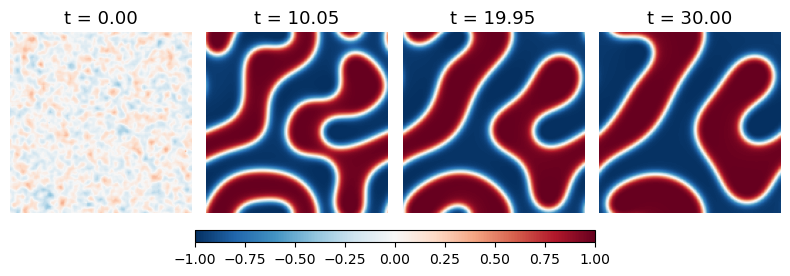

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(8, 3))

pidx = [0, (len(snapshots))//3, 2*(len(snapshots)-1)//3, -1]
for ax, idx in zip(axes, pidx):
    im = ax.imshow(snapshots[idx], cmap='RdBu_r', vmin=-1, vmax=1,
                   origin='lower', extent=[0, L, 0, L])
    ax.set_title(f't = {times[idx]:.2f}', fontsize=13)
    ax.axis('off')

cbar_ax = fig.add_axes([0.25, 0.1, 0.5, 0.04])
fig.colorbar(im, cax=cbar_ax, orientation='horizontal')

plt.tight_layout()
plt.savefig('../../latex/figures/cahn_hilliard_snapshots.pdf', bbox_inches='tight')
print('saved dynamics figure')


## 2. Extract data for regression

Central finite difference for $f_t$, random subsampling of spatial points.

In [24]:
n_per_snap = 200

f_snaps, ft_snaps, idx_sets, dt_snap = make_regression_data(
    snapshots, times, n_per_snap=n_per_snap, seed=0,
)

Ft_all = np.concatenate([ft_snaps[s].ravel()[idx_sets[s]] for s in range(len(f_snaps))])
print(f'{len(f_snaps)} interior snapshots, dt_snap = {dt_snap:.4f}')
print(f'Total regression points: {len(Ft_all)}')


199 interior snapshots, dt_snap = 0.1500
Total regression points: 39800


## 3. Libraries of differential terms

We evaluate the equivariant and standard library matrices for each snapshot.

In [25]:
Theta_eq_rows_spec, Theta_std_rows_spec = [], []
Theta_eq_rows_poly, Theta_std_rows_poly = [], []

for s in range(len(f_snaps)):
    fs  = f_snaps[s]
    idx = idx_sets[s]
    with derivatives.use_backend('spectral'):
        Th_eq,  desc_eq  = build_equivariant_library(fs, L, L)
        Th_std, desc_std = build_standard_library(fs, L, L, max_order=4, max_poly=3)
    Theta_eq_rows_spec.append(Th_eq[idx])
    Theta_std_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq,  _ = build_equivariant_library(fs, L, L)
        Th_std, _ = build_standard_library(fs, L, L, max_order=4, max_poly=3)
    Theta_eq_rows_poly.append(Th_eq[idx])
    Theta_std_rows_poly.append(Th_std[idx])

Theta_eq_spec  = np.vstack(Theta_eq_rows_spec).astype(float)
Theta_std_spec = np.vstack(Theta_std_rows_spec).astype(float)
Theta_eq_poly  = np.vstack(Theta_eq_rows_poly).astype(float)
Theta_std_poly = np.vstack(Theta_std_rows_poly).astype(float)

print(f'Library shape : {Theta_eq_spec.shape}')
print(f'Condition numbers (eq / std):')
print(f'  Spectral:   {np.linalg.cond(Theta_eq_spec):.2e} / {np.linalg.cond(Theta_std_spec):.2e}')
print(f'  Polynomial: {np.linalg.cond(Theta_eq_poly):.2e} / {np.linalg.cond(Theta_std_poly):.2e}')


Library shape : (39800, 20)
Condition numbers (eq / std):
  Spectral:   1.61e+04 / 1.31e+04
  Polynomial: 7.52e+03 / 6.69e+03


## 4. Sparse regression (STRidge)

True PDE: $f_t = -\Delta f + 3f^2\Delta f + 6f|\nabla f|^2 - \varepsilon^2\Delta^2 f$

In [26]:
lam   = 1e-5
d_tol = 0.05

print('=== Ground truth PDE ===')
print(f'f_t = -Δf + 3f²Δf + 6f|∇f|² - {eps**2:.4f}Δ²f\n')

print('── Spectral derivatives ──')
w_eq_spec  = TrainSTRidge(Theta_eq_spec,  Ft_all, lam, d_tol)
w_std_spec = TrainSTRidge(Theta_std_spec, Ft_all, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_spec, desc_eq)
print('Standard:');   print_pde(w_std_spec, desc_std)

print('\n── Polynomial derivatives ──')
w_eq_poly  = TrainSTRidge(Theta_eq_poly,  Ft_all, lam, d_tol)
w_std_poly = TrainSTRidge(Theta_std_poly, Ft_all, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_poly, desc_eq)
print('Standard:');   print_pde(w_std_poly, desc_std)


=== Ground truth PDE ===
f_t = -Δf + 3f²Δf + 6f|∇f|² - 0.0400Δ²f

── Spectral derivatives ──
Equivariant:
f_t = (-0.00404)1 + (-0.11116)f + (+0.00342)f² + (+0.11050)f³ + (-0.88617)Δf + (-0.00879)f·Δf + (-0.00729)‖∇f‖² + (+2.54383)f²·Δf + (+5.18121)f·‖∇f‖² + (-0.03539)Δ²f + (+0.00015)f·Δ²f + (-0.00031)Δf·Δf + (-0.00015)‖∇²f‖² + (-0.00029)⟨∇Δf,∇f⟩ + (+0.00210)f²·Δ²f + (-0.00733)f·Δf·Δf + (+0.00132)f·‖∇²f‖² + (-0.00399)f·⟨∇Δf,∇f⟩ + (-0.00249)‖∇f‖²·Δf + (+0.00116)∇²f(∇f,∇f)
Standard:
f_t = (+2.71177)1 + (+0.04511)f_y + (+0.08422)f_yy + (+0.09002)f_xx + (+0.00191)f_yyy + (+0.00184)f_xxy + (-0.00027)f_yyyy + (-0.00023)f_xxyy + (-0.00023)f_xxxx + (+0.42531)f + (+0.14560)f·f_y + (+0.25241)f·f_x + (+0.01336)f·f_yy + (-0.00541)f·f_xx + (+0.00566)f·f_yyy + (+0.00877)f·f_xyy + (+0.00576)f·f_xxy + (+0.01044)f·f_xxx + (+0.00025)f·f_yyyy + (-0.00027)f·f_xxxx + (-2.75820)f^2 + (-0.14086)f^2·f_y + (+0.03120)f^2·f_yy + (+0.02121)f^2·f_xx + (-0.00103)f^2·f_xxyy + (-0.41058)f^3 + (-0.43361)f^3·f_y + (-0.7

In [7]:
# Summary comparison — define true_eq for reuse in later cells
true_eq = np.zeros(len(desc_eq))
true_eq[4]  = -1.0       # N4  = Δf
true_eq[6]  = 3.0        # N6  = f² Δf
true_eq[8]  = 6.0        # N8  = f |∇f|²
true_eq[10] = -(eps**2)  # N10 = Δ²f
act = np.abs(true_eq) > 1e-10

print('--- Recovery summary (clean data) ---')
print(f'True: N4(Δf)→-1, N6(f²Δf)→+3, N8(f|∇f|²)→+6, N10(Δ²f)→-{eps**2:.4f}\n')

for tag, w in [('Spectral  eq', w_eq_spec), ('Polynomial eq', w_eq_poly)]:
    nz  = np.count_nonzero(np.abs(w) > 1e-10)
    fp  = int(np.sum((np.abs(w) > 1e-10) & ~act))
    fn  = int(np.sum((np.abs(w) < 1e-10) &  act))
    err = float(np.max(np.abs(w[act] - true_eq[act])))
    print(f'  {tag}: {nz} active, fp={fp}, fn={fn}, max_coeff_err={err:.3e}')

for tag, w in [('Spectral  std', w_std_spec), ('Polynomial std', w_std_poly)]:
    nz = np.count_nonzero(np.abs(w) > 1e-10)
    print(f'  {tag}: {nz} active terms out of {len(w)}')


--- Recovery summary (clean data) ---
True: N4(Δf)→-1, N6(f²Δf)→+3, N8(f|∇f|²)→+6, N10(Δ²f)→-0.0064

  Spectral  eq: 20 active, fp=16, fn=0, max_coeff_err=5.677e+00
  Polynomial eq: 20 active, fp=16, fn=0, max_coeff_err=6.055e+00
  Spectral  std: 35 active terms out of 60
  Polynomial std: 54 active terms out of 60


## 5. Robustness to noise

We benchmark with added **observation noise**.

In [8]:
noise_level = 0.02   # 2% of clean snapshot std

snapshots_noisy, _ = cahn_hilliard(
    N=N, L=L, T_end=T_end, eps=eps, dt=dt, save_every=save_every, seed=42,
    obs_noise=noise_level,
)

f_snaps_n, ft_snaps_n, idx_sets_n, _ = make_regression_data(
    snapshots_noisy, times, n_per_snap=n_per_snap, seed=0,
)
Ft_n = np.concatenate([ft_snaps_n[s].ravel()[idx_sets_n[s]] for s in range(len(f_snaps_n))])

Theta_eq_n_rows_spec, Theta_std_n_rows_spec = [], []
Theta_eq_n_rows_poly, Theta_std_n_rows_poly = [], []

for s in range(len(f_snaps_n)):
    idx = idx_sets_n[s]
    with derivatives.use_backend('spectral'):
        Th_eq, _  = build_equivariant_library(f_snaps_n[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_n[s], L, L, max_order=4, max_poly=3)
    Theta_eq_n_rows_spec.append(Th_eq[idx])
    Theta_std_n_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq, _  = build_equivariant_library(f_snaps_n[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_n[s], L, L, max_order=4, max_poly=3)
    Theta_eq_n_rows_poly.append(Th_eq[idx])
    Theta_std_n_rows_poly.append(Th_std[idx])

Theta_eq_n_spec  = np.vstack(Theta_eq_n_rows_spec).astype(float)
Theta_std_n_spec = np.vstack(Theta_std_n_rows_spec).astype(float)
Theta_eq_n_poly  = np.vstack(Theta_eq_n_rows_poly).astype(float)
Theta_std_n_poly = np.vstack(Theta_std_n_rows_poly).astype(float)
print(f'Noisy: {len(Ft_n)} regression points, noise={noise_level*100:.0f}%')


Noisy: 39800 regression points, noise=2%


In [9]:
print(f'── Spectral (obs_noise = {noise_level*100:.0f}%) ──')
w_eq_n_spec  = TrainSTRidge(Theta_eq_n_spec,  Ft_n, lam, d_tol)
w_std_n_spec = TrainSTRidge(Theta_std_n_spec, Ft_n, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_n_spec, desc_eq)
print('Standard:');   print_pde(w_std_n_spec, desc_std)

print(f'\n── Polynomial (obs_noise = {noise_level*100:.0f}%) ──')
w_eq_n_poly  = TrainSTRidge(Theta_eq_n_poly,  Ft_n, lam, d_tol)
w_std_n_poly = TrainSTRidge(Theta_std_n_poly, Ft_n, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_n_poly, desc_eq)
print('Standard:');   print_pde(w_std_n_poly, desc_std)

print('\n--- Noisy recovery summary ---')
for tag, w in [('Spectral  eq', w_eq_n_spec), ('Polynomial eq', w_eq_n_poly)]:
    fp  = int(np.sum((np.abs(w) > 1e-10) & ~act))
    fn  = int(np.sum((np.abs(w) < 1e-10) &  act))
    err = float(np.max(np.abs(w[act] - true_eq[act])))
    print(f'  {tag}: fp={fp}, fn={fn}, max_coeff_err={err:.3e}')


── Spectral (obs_noise = 2%) ──
Equivariant:
f_t = (+1.41804)f + (-0.03673)f² + (-1.44471)f³ + (+0.02817)Δf + (-0.00154)f·Δf + (-0.00348)‖∇f‖² + (-0.02895)f²·Δf + (+0.02448)f·‖∇f‖² + (+0.00004)Δ²f + (-0.00000)f·Δ²f + (+0.00001)Δf·Δf + (-0.00002)‖∇²f‖² + (-0.00000)⟨∇Δf,∇f⟩ + (-0.00003)f²·Δ²f + (-0.00008)f·Δf·Δf + (+0.00005)f·‖∇²f‖² + (-0.00002)f·⟨∇Δf,∇f⟩ + (+0.00045)‖∇f‖²·Δf + (-0.00031)∇²f(∇f,∇f)
Standard:
f_t = (+2.50719)1 + (-0.00184)f_y + (+0.03385)f_yy + (+0.00783)f_xy + (+0.03449)f_xx + (-0.00005)f_xxy + (+0.00004)f_yyyy + (+0.00001)f_xyyy + (+0.00002)f_xxyy + (+0.00001)f_xxxy + (+0.00004)f_xxxx + (-0.34071)f + (+0.01317)f·f_x + (-0.00255)f·f_yy + (-0.01338)f·f_xy + (-0.00778)f·f_xx + (+0.00006)f·f_yyy + (+0.00003)f·f_xyy + (+0.00003)f·f_xxy + (+0.00004)f·f_xxx + (-0.00001)f·f_yyyy + (-0.00002)f·f_xyyy + (+0.00001)f·f_xxyy + (-0.00000)f·f_xxxy + (-0.00001)f·f_xxxx + (-2.53669)f^2 + (-0.02826)f^2·f_yy + (-0.01309)f^2·f_xy + (-0.03332)f^2·f_xx + (+0.00005)f^2·f_xxy + (-0.00002)f^2·f

## 6. Equivariance test

We rotate the data by 90° and repeat the regression.

In [10]:
# Rotate all snapshots 90° and re-run the same pipeline
snaps_r = rotation_90(snapshots.transpose(1, 2, 0)).transpose(2, 0, 1)

f_snaps_r, ft_snaps_r, idx_sets_r, _ = make_regression_data(
    snaps_r, times, n_per_snap=n_per_snap, seed=0,
)
Ft_r = np.concatenate([ft_snaps_r[s].ravel()[idx_sets_r[s]] for s in range(len(f_snaps_r))])

Theta_eq_r_rows_spec, Theta_std_r_rows_spec = [], []
Theta_eq_r_rows_poly, Theta_std_r_rows_poly = [], []

for s in range(len(f_snaps_r)):
    idx = idx_sets_r[s]
    with derivatives.use_backend('spectral'):
        Th_eq, _  = build_equivariant_library(f_snaps_r[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_r[s], L, L, max_order=4, max_poly=3)
    Theta_eq_r_rows_spec.append(Th_eq[idx])
    Theta_std_r_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq, _  = build_equivariant_library(f_snaps_r[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_r[s], L, L, max_order=4, max_poly=3)
    Theta_eq_r_rows_poly.append(Th_eq[idx])
    Theta_std_r_rows_poly.append(Th_std[idx])

Theta_eq_r_spec  = np.vstack(Theta_eq_r_rows_spec).astype(float)
Theta_std_r_spec = np.vstack(Theta_std_r_rows_spec).astype(float)
Theta_eq_r_poly  = np.vstack(Theta_eq_r_rows_poly).astype(float)
Theta_std_r_poly = np.vstack(Theta_std_r_rows_poly).astype(float)

print('── Spectral (rotated clean) ──')
w_eq_r_spec  = TrainSTRidge(Theta_eq_r_spec,  Ft_r, lam, d_tol)
w_std_r_spec = TrainSTRidge(Theta_std_r_spec, Ft_r, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_r_spec, desc_eq)
print('Standard:');   print_pde(w_std_r_spec, desc_std)

print('\n── Polynomial (rotated clean) ──')
w_eq_r_poly  = TrainSTRidge(Theta_eq_r_poly,  Ft_r, lam, d_tol)
w_std_r_poly = TrainSTRidge(Theta_std_r_poly, Ft_r, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_r_poly, desc_eq)
print('Standard:');   print_pde(w_std_r_poly, desc_std)


── Spectral (rotated clean) ──
Equivariant:
f_t = (-0.32835)1 + (+2.38241)f + (+0.27606)f² + (-2.40197)f³ + (-0.03955)Δf + (-0.00185)f·Δf + (-0.00210)‖∇f‖² + (+0.05981)f²·Δf + (+0.30427)f·‖∇f‖² + (-0.00005)Δ²f + (-0.00002)Δf·Δf + (+0.00001)‖∇²f‖² + (-0.00002)⟨∇Δf,∇f⟩ + (+0.00002)f²·Δ²f + (-0.00038)f·Δf·Δf + (-0.00061)f·‖∇²f‖² + (-0.00020)f·⟨∇Δf,∇f⟩ + (+0.00188)‖∇f‖²·Δf + (+0.00072)∇²f(∇f,∇f)
Standard:
f_t = (+6.22037)1 + (-0.00203)f_y + (-0.00018)f_x + (+0.08125)f_yy + (-0.02037)f_xy + (+0.07176)f_xx + (+0.00008)f_yyy + (-0.00005)f_xyy + (-0.00012)f_xxy + (-0.00002)f_xxx + (+0.00009)f_yyyy + (-0.00005)f_xyyy + (+0.00009)f_xxyy + (-0.00005)f_xxxy + (+0.00007)f_xxxx + (-1.01133)f + (+0.00449)f·f_y + (-0.00548)f·f_x + (-0.00487)f·f_yy + (+0.01079)f·f_xy + (+0.00450)f·f_xx + (+0.00006)f·f_yyy + (-0.00005)f·f_xyy + (+0.00008)f·f_xxy + (-0.00006)f·f_xxx + (-0.00003)f·f_yyyy + (-0.00004)f·f_xyyy + (-0.00003)f·f_xxyy + (+0.00005)f·f_xxxy + (-0.00000)f·f_xxxx + (-6.26117)f^2 + (+0.01147)f^2·f_y

In [11]:
print('Coefficient change under 90° rotation (clean data):')
for tag, w, wr in [
    ('Spectral  eq',  w_eq_spec,  w_eq_r_spec),
    ('Polynomial eq', w_eq_poly,  w_eq_r_poly),
    ('Spectral  std', w_std_spec, w_std_r_spec),
    ('Polynomial std',w_std_poly, w_std_r_poly),
]:
    print(f'  {tag}: max|Δc| = {np.max(np.abs(w - wr)):.2e}')


Coefficient change under 90° rotation (clean data):
  Spectral  eq: max|Δc| = 3.58e-01
  Polynomial eq: max|Δc| = 1.01e+00
  Spectral  std: max|Δc| = 1.58e-01
  Polynomial std: max|Δc| = 6.04e-01
